# AutoBio Notebook 05: A Dyna-Style Closed Loop for World-Gymnast

**一个已实现、可独立测试的最小闭环：候选策略 → 模型预测 → Simulator 反馈 → 奖励判断修正 → 真实配对评价。**

当前交付是 **CPU 验证通过的实现版本**。尚未执行新的 AutoBio/MuJoCo 实验：公开仓库和本工作区缺少 Stage 4 策略、latent model 权重及其原始源码。下面会实际运行记录核验、候选生成、测试和资源检查；不会把历史记录或测试夹具当作新实验结果。

本轮沿用 11 月 4 日的执行任务书，并按 11 月 6 日要求缩小为一轮闭环。优化方法是**有限候选策略搜索**，模型更新是**成功奖励修正头**。GRPO 与 latent dynamics 微调尚未实现；这里不宣称完成完整 World-Gymnast 复现。

[实现与运行说明](docs/notebook05.md) · [可行性核对](reports/notebook05_feasibility.md) · [闭环代码](dyna05/core.py)

## 1. Goal — 从 9 次虚假成功开始

Notebook 04 比较的是同一个冻结控制器在两个反馈回路里的判断。90 次实际成功与 95 次预测成功之间，不只是 5 次的数量差异：10 次真实失败中，有 9 次被模型错判为成功。

先从保存的 **100 条历史配对记录**重新计算混淆矩阵。这个步骤不运行物理仿真。

In [1]:
from pathlib import Path
import json, sys, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / 'dyna05').is_dir():
    ROOT = ROOT.parent
assert (ROOT / 'dyna05').is_dir(), 'Run this notebook from the repository root.'
sys.path.insert(0, str(ROOT))
from dyna05.audit import audit_stage4
from dyna05.assets import preflight
from dyna05.core import Config, generate_candidates, RewardCorrection, run_cycle

historical = audit_stage4(ROOT)
metrics = historical['metrics']
table = pd.DataFrame([[metrics['tp'], metrics['fn']], [metrics['fp'], metrics['tn']]],
                     index=['Simulator success', 'Simulator failure'],
                     columns=['Model success', 'Model failure'])
display(table)
print(f"Historical records: {metrics['n']}; checked files: {historical['checked_files']}.")
print(f"Failure recall: {metrics['failure_recall']:.1%}; false success among actual failures: {metrics['false_success_among_failures']:.1%}.")
print('New simulator runs in this cell: 0.')

Historical records: 100; checked files: 25.
Failure recall: 10.0%; false success among actual failures: 90.0%.
New simulator runs in this cell: 0.


,Model success,Model failure
Simulator success,86,4
Simulator failure,9,1


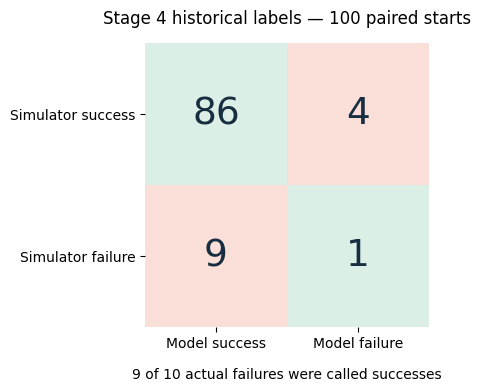

In [2]:
fig, ax = plt.subplots(figsize=(6.8, 3.8), constrained_layout=True)
values = table.to_numpy()
colors = np.array([[0., 1.], [1., 0.]])
from matplotlib.colors import ListedColormap
ax.imshow(colors, cmap=ListedColormap(['#dcefe7', '#f9dfd8']), vmin=0, vmax=1)
for i in range(2):
    for j in range(2):
        ax.text(j, i, str(values[i, j]), ha='center', va='center', fontsize=27, color='#172d40')
ax.set_xticks([0, 1], ['Model success', 'Model failure'])
ax.set_yticks([0, 1], ['Simulator success', 'Simulator failure'])
ax.set_title('Stage 4 historical labels — 100 paired starts', pad=14)
ax.set_xlabel('9 of 10 actual failures were called successes', labelpad=12)
for spine in ax.spines.values():
    spine.set_visible(False)
plt.show()

**这个矩阵说明为什么需要真实验证，不能说明候选策略能否被正确排序。** `run_cycle` 额外记录同一起点内候选的 pairwise ordering accuracy 和零方差组。真实结果相同的候选对不参与排序计分；模型打平记为 0.5。

## 2. Setup — 复用到哪一层？

| 项目 | 本轮接口与范围 |
|---|---|
| 冻结基线 | Stage 4 状态学生策略 `dense50_10000.pt`＋原 lift rule；不是把 latent 向量塞给图像 ACT |
| 动作 | 原始策略提出 50×7，由原控制器消费为 10×7 物理命令包，每包 0.2 秒 |
| 模型 | Stage 4 tube-specific latent model，repair_v2 step 8000；不是 PickCube 权重 |
| 成功条件 | 同一步 height > 0.925 m 且 contact；Simulator 使用 `task.check()`，模型 contact ≥ 0.5 |
| 本轮时长 | 两个回路统一为 112 包＝22.4 秒；历史失败片段分别到 22.5/22.6 秒，因此不声称逐数重现 90/100 |
| 本轮策略更新 | 冻结反馈控制器＋有界固定残差；候选选择改变实际执行策略，不更新学生网络权重 |
| 本轮模型更新 | 真实反馈训练成功奖励修正头；latent 转移保持冻结 |

### Key assumptions

原始状态顺序、归一化、chunk 消费和 lift 时序必须由原代码导入。只有 checkpoint 文件而没有这些接口，仍不足以运行正确实验。独立初始状态必须与原训练/开发 seed 清单交叉核验。

In [3]:
from dataclasses import asdict
config = Config(**json.loads((ROOT / 'configs/notebook05.json').read_text()))
config.check()
candidates = generate_candidates(config.candidates, config.residual_radius, config.candidate_seed)
candidate_table = pd.DataFrame([
    {'policy': c.name, **{f'joint_{j+1}': v for j, v in enumerate(c.residual_fraction)}}
    for c in candidates
])
display(candidate_table.round(5))
print('Residuals are fractions of physical actuator range; joint_7 (gripper) stays zero.')
print('Baseline + antithetic candidates are deterministic. No policy/model inference has run.')

Residuals are fractions of physical actuator range; joint_7 (gripper) stays zero.
Baseline + antithetic candidates are deterministic. No policy/model inference has run.


,policy,joint_1,joint_2,joint_3,joint_4,joint_5,joint_6,joint_7
0,baseline,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.0
1,candidate_01,0.00878,0.01000,-0.00990,0.00128,0.00176,0.00291,0.0
2,candidate_02,-0.00878,-0.01000,0.00990,-0.00128,-0.00176,-0.00291,-0.0
3,candidate_03,-0.01000,0.00543,-0.00138,0.00411,-0.00252,0.00203,0.0
4,candidate_04,0.01000,-0.00543,0.00138,-0.00411,0.00252,-0.00203,-0.0


## 3. One iteration — 闭环实际做什么？

`dyna05/core.py:run_cycle` 执行如下顺序。模型想象和 Simulator 执行分别保存完整轨迹，原始判断和修正判断也分别保留。

1. **Collect：**各候选从同一物理起点进入两条闭环，收集模型预测和实际成功标签。
2. **Correct：**以真实 collection 标签拟合 logistic 成功判断修正头；只在独立 validation 上 Brier 改善、FP/FN 均不增加时采用，否则保留原模型判断。
3. **Search：**在新的起点用原始或修正后的模型分数给候选排序，选出两个挑战者。
4. **Confirm：**基线与挑战者在同一组新 Simulator 起点运行；只有真实成功次数严格增加才替换基线。
5. **Test：**先保存已选策略，再获取最终起点；对基线与更新策略做相同 snapshot 的真实配对评价，不根据 test 结果重新选策略。

每条 imagined rollout 只在起点读取一次实际 observation。随后控制器看到的是模型自己的下一状态。修正头只影响候选评分，不会修复 imagined trajectory 内部的状态漂移。

In [4]:
split_names = ['collect', 'validate', 'search', 'confirm', 'test']
display(pd.DataFrame([
    {'split': name, 'n_states': len(getattr(config, name)),
     'first_seed': min(getattr(config, name)), 'last_seed': max(getattr(config, name))}
    for name in split_names
]))
max_sim = config.candidates * (len(config.collect) + len(config.validate)) + (1 + config.verify_top_k) * len(config.confirm) + 2 * len(config.test)
max_model = max_sim + config.candidates * len(config.search)
print(f'Bounded round: at most {max_sim} simulator episodes and {max_model} imagined episodes.')
print(f'Common horizon: {config.horizon_packets} packets = {config.horizon_packets * .2:.1f} seconds.')

Bounded round: at most 72 simulator episodes and 92 imagined episodes.
Common horizon: 112 packets = 22.4 seconds.


,split,n_states,first_seed,last_seed
0,collect,4,11061000,11061003
1,validate,4,11062000,11062003
2,search,4,11063000,11063003
3,confirm,4,11064000,11064003
4,test,10,11065000,11065009


## 4. Checks — 执行独立验证

下面运行真实的 Python 测试，包括：动作边界、固定起点恢复、闭环反馈、终止与轨迹对齐、奖励来源隔离、数据划分、修正头保存/加载、接受/拒绝更新路径、最终测试在选策后才开始，以及“模型全报成功、实际全失败”时必须保留基线。

这些测试使用明确标记的 **synthetic fixtures**，只验证程序逻辑。MuJoCo adapter 的调度测试验证每包 100 次 physics-step 调用；没有安装真实引擎时，它不代表物理兼容性测试。

In [5]:
check = subprocess.run([sys.executable, '-m', 'pytest', 'tests/test_dyna05.py', '-q'],
                       cwd=ROOT, capture_output=True, text=True)
print(check.stdout.strip())
if check.returncode:
    print(check.stderr[-4000:])
assert check.returncode == 0, 'Contract validation failed.'

............................                                             [100%]
28 passed in 1.50s


## 5. Real execution — 检查必要资源

默认 manifest 列出需要从原实验机器导入的文件。这里的 BLOCKED 是资源检查结果，不能用演示数据自动绕过。

需要：冻结 state-student 权重、repair_v2 step 8000 权重、原 controller/model 源码与归一化、训练/开发 seed 清单、运行 AutoBio 的环境，以及将原架构接到本包的 bridge。完整接口见 [运行说明](docs/notebook05.md#exact-bridge-contract)。

In [6]:
ASSETS = ROOT / 'configs/notebook05_assets.example.json'
availability = preflight(ASSETS)
print('Real execution status:', availability['status'])
display(pd.DataFrame({'missing prerequisite': availability['blockers']}))

Real execution status: BLOCKED


,missing prerequisite
0,policy_checkpoint: path not supplied
1,world_model_checkpoint: path not supplied
2,state_action_schema: path not supplied
3,training_seed_manifest: path not supplied
4,bridge_source: path not supplied
5,dependency missing: torch
6,dependency missing: mujoco
7,Original Stage 4 controller/model class defini...


资源准备好后，把 `ASSETS` 改为实际的 `notebook05_assets.local.json`，再将 `RUN_REAL` 改为 `True`。输出目录必须是新目录，防止覆盖已有证据。此操作最多运行上面计算的固定预算。

默认 CPU 执行不会发起下载或训练。真实入口没有 synthetic fallback。

In [7]:
RUN_REAL = False
OUTPUT = ROOT / 'runs/notebook05_round1'
if RUN_REAL:
    assert not availability['blockers'], 'Supply and validate the original Stage 4 assets first.'
    command = [sys.executable, '-m', 'dyna05.cli', 'run', '--assets', str(ASSETS),
               '--config', str(ROOT / 'configs/notebook05.json'), '--output', str(OUTPUT)]
    subprocess.run(command, cwd=ROOT, check=True)
    result = json.loads((OUTPUT / 'result.json').read_text())
    assert result['status'] == 'COMPLETE' and result['evidence_kind'] == 'mujoco'
    display(pd.DataFrame([result['paired_policy_evaluation']]))
    display(pd.DataFrame([
        {'policy': policy, 'predictor': predictor, **values}
        for policy, versions in result['heldout_model_errors'].items()
        for predictor, values in versions.items()
    ]))
else:
    print('No new AutoBio/MuJoCo experiment executed. Updated success rate and model-error change are unknown.')

No new AutoBio/MuJoCo experiment executed. Updated success rate and model-error change are unknown.


## 6. Takeaways — 已完成什么，下一步接什么？

本 notebook 已经能从头执行历史核验、候选生成、完整闭环逻辑测试和资源预检；闭环代码会保存实际奖励、预测误差、轨迹和冻结的最终策略。**本次没有新的 MuJoCo 成功率，也没有证明模型或策略已改善。**

接入原始 Stage 4 bundle 后，运行上面的 real cell 即可执行这一轮。最终应读取 `result.json` 的 Simulator 配对结果，检查更新后真实成功率是否提高，以及 raw/corrected 模型 FP/FN 是否改善；如果没有改善，保留该负结果。

后续扩展点是原始 latent dynamics 的 transition loss 和可定义正确 likelihood 的随机策略。它们可复用现在保存的真实轨迹、划分与评价逻辑，而不需要再次从架构图开始。